# GUIDE and CART on scikit-learn's classification datasets

This notebook compares `GuideClassifier` with scikit-learn's `DecisionTreeClassifier`, which implements CART, on the iris, wine and breast cancer datasets bundled with scikit-learn.

The two methods differ in how they choose splits:

- **CART** searches every variable and every cutpoint for the split that most reduces impurity. Variables with many distinct values offer more candidate splits, so they win more often, even when they carry no information (see the selection bias notebook).
- **GUIDE** first picks the split *variable* with chi-square tests of association between the response and each predictor (plus pairwise interaction tests), then searches only that variable for the best split point.

By default, scikit-learn grows CART trees until the leaves are pure, while GUIDE prunes by 10-fold cross-validation. For a fair comparison we also tune CART's cost-complexity parameter `ccp_alpha` by cross-validation.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer, load_iris, load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree as plot_cart

from guide import GuideClassifier, GuideForestClassifier, plot_tree

## Iris

`plot_tree` draws a fitted GUIDE tree with matplotlib. Each internal node shows its split condition; samples that satisfy it go left ("yes").

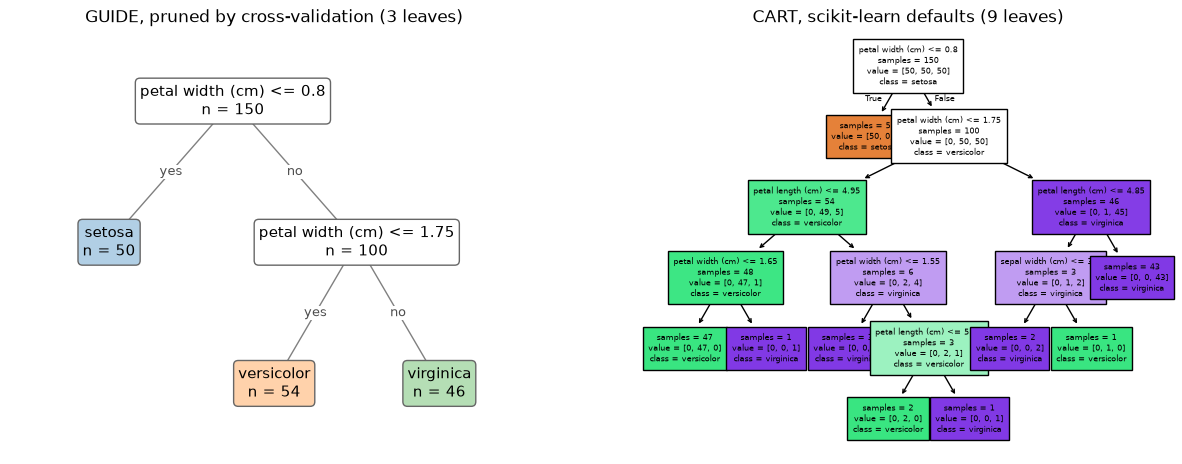

In [2]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target.map(dict(enumerate(iris.target_names)))

guide = GuideClassifier().fit(X, y)
cart = DecisionTreeClassifier(random_state=0).fit(X, y)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_tree(guide, ax=axes[0])
axes[0].set_title(f"GUIDE, pruned by cross-validation ({guide.get_n_leaves()} leaves)")
plot_cart(cart, feature_names=list(X.columns), class_names=list(cart.classes_), filled=True,
          impurity=False, fontsize=6, ax=axes[1])
axes[1].set_title(f"CART, scikit-learn defaults ({cart.get_n_leaves()} leaves)")
plt.show()

The same tree as text, including the leaf class probabilities and the route taken by missing values:

In [3]:
print(guide.to_text())

guide-rs-0.1-experimental-reference12
1 tree(s), 3 fitted leaves
Tree 1
node 0 (n=150): petal width (cm) <= 0.800000; missing -> no
  node 1 (n=50): class "setosa"; p=[0.9955849889624725, 0.002207505518763797, 0.002207505518763797]
  node 2 (n=100): petal width (cm) <= 1.750000; missing -> no
    node 3 (n=54): class "versicolor"; p=[0.002207505518763797, 0.9036055923473143, 0.09418690213392202]
    node 12 (n=46): class "virginica"; p=[0.002207505518763797, 0.02380266820232268, 0.9739898262789137]



## Accuracy and tree size

Ten-fold cross-validated accuracy, with the mean number of leaves and the mean fit time across folds. "CART, tuned" chooses `ccp_alpha` by an inner 5-fold grid search, the closest analog of GUIDE's built-in pruning.

In [4]:
def leaves(model):
    model = getattr(model, "best_estimator_", model)
    return model.get_n_leaves() if hasattr(model, "get_n_leaves") else np.nan


def compare(models, X, y, cv, scoring=None):
    rows = []
    for name, model in models.items():
        result = cross_validate(model, X, y, cv=cv, scoring=scoring, return_estimator=True)
        rows.append({
            "model": name,
            "score": result["test_score"].mean(),
            "sd": result["test_score"].std(),
            "leaves": np.mean([leaves(e) for e in result["estimator"]]),
            "fit seconds": result["fit_time"].mean(),
        })
    return pd.DataFrame(rows).set_index("model").round(3)


def cart_tuned():
    grid = {"ccp_alpha": np.r_[0, np.logspace(-4, -1, 12)]}
    return GridSearchCV(DecisionTreeClassifier(random_state=0), grid, cv=5)


models = {
    "GUIDE": GuideClassifier(),
    "CART, defaults": DecisionTreeClassifier(random_state=0),
    "CART, tuned": cart_tuned(),
}
def named(bunch):
    return bunch.data, bunch.target.map(dict(enumerate(bunch.target_names)))


datasets = {
    "iris": (X, y),
    "wine": named(load_wine(as_frame=True)),
    "breast cancer": named(load_breast_cancer(as_frame=True)),
}
cv = StratifiedKFold(10, shuffle=True, random_state=0)
pd.concat({name: compare(models, *data, cv) for name, data in datasets.items()})

score     sd  leaves  fit seconds
              model                                            
iris          GUIDE           0.933  0.060     3.8        0.001
              CART, defaults  0.940  0.055     8.6        0.001
              CART, tuned     0.933  0.060     5.6        0.064
wine          GUIDE           0.916  0.079     5.0        0.002
              CART, defaults  0.882  0.077     9.4        0.001
              CART, tuned     0.871  0.097     8.5        0.081
breast cancer GUIDE           0.935  0.039     8.1        0.026
              CART, defaults  0.923  0.040    21.0        0.004
              CART, tuned     0.933  0.044     7.2        0.218

Accuracy is similar across methods, as is typical for single trees on these datasets, with GUIDE ahead on wine. The trees differ more in size: unpruned CART trees are two to three times larger.

On the breast cancer data GUIDE is slower than default CART but faster than CART tuned by grid search; its cross-validation folds run in parallel. When an interaction test selects a pair of predictors, GUIDE scores each split on the first by the best split on the second in each child, a one-level lookahead; `interactions=False` skips the interaction tests and the lookahead.

## Breast cancer trees

GUIDE's variable selection and CART's exhaustive search can pick different root variables even when both trees predict well. Restricting both to depth 3 for display:

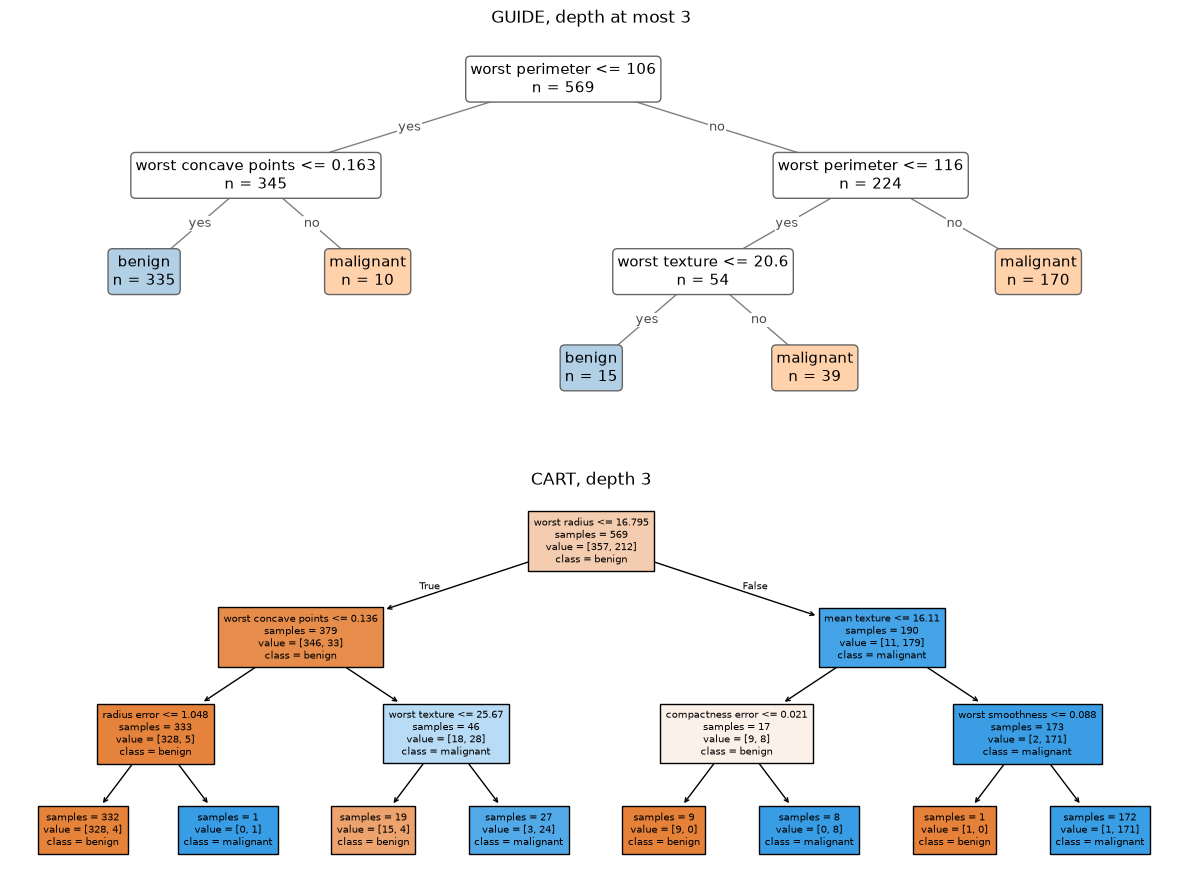

In [5]:
Xb, yb = datasets["breast cancer"]
guide_b = GuideClassifier(max_depth=3).fit(Xb, yb)
cart_b = DecisionTreeClassifier(max_depth=3, random_state=0).fit(Xb, yb)

fig, axes = plt.subplots(2, 1, figsize=(15, 11))
plot_tree(guide_b, ax=axes[0])
axes[0].set_title("GUIDE, depth at most 3")
plot_cart(cart_b, feature_names=list(Xb.columns), class_names=list(cart_b.classes_), filled=True,
          impurity=False, fontsize=7, ax=axes[1])
axes[1].set_title("CART, depth 3")
plt.show()

## Forests

`GuideForestClassifier` fits GUIDE trees to bootstrap samples, sampling candidate split variables at each node (by default the square root of their number). It is compared here with `RandomForestClassifier`, both with 100 trees fitted on all cores, by 5-fold cross-validation.

In [6]:
forests = {
    "GUIDE forest": GuideForestClassifier(n_estimators=100),
    "random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=0),
}
cv5 = StratifiedKFold(5, shuffle=True, random_state=0)
pd.concat({name: compare(forests, *datasets[name], cv5).drop(columns="leaves")
           for name in ["wine", "breast cancer"]})

score     sd  fit seconds
              model                                   
wine          GUIDE forest   0.983  0.014        0.006
              random forest  0.972  0.018        0.051
breast cancer GUIDE forest   0.958  0.022        0.054
              random forest  0.965  0.015        0.048

The two forests are about equally accurate; the GUIDE forest takes longer to fit for the reason given above. The GUIDE forest's out-of-bag loss (here the misclassification rate, since no costs are given) estimates its error without a separate test set:

In [7]:
forest = GuideForestClassifier(n_estimators=100).fit(Xb, yb)
print(f"out-of-bag error: {forest.oob_loss_:.3f}")

out-of-bag error: 0.040
